In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
print("NumPy:", np.__version__)

NumPy: 2.5.3


In [2]:
x, y = 1.0, 1.0
w, b, v = 0.5, 0.0, 1.0
z = w*x + b
h = sigmoid(z)
y_hat = v*h
loss = 0.5*(y_hat-y)**2
print(f"z={z:.4f}, h={h:.4f}, prediction={y_hat:.4f}, loss={loss:.6f}")

z=0.5000, h=0.6225, prediction=0.6225, loss=0.071268


In [3]:
dL_dyhat = y_hat - y
dyhat_dh = v
dh_dz = h*(1-h)
dz_dw = x
grad = dL_dyhat*dyhat_dh*dh_dz*dz_dw
def scalar_loss(weight):
    return 0.5*(v*sigmoid(weight*x+b)-y)**2
eps = 1e-5
numeric_grad = (scalar_loss(w+eps)-scalar_loss(w-eps))/(2*eps)
print("four factors:", dL_dyhat, dyhat_dh, dh_dz, dz_dw)
print(f"chain rule={grad:.6f}, numerical={numeric_grad:.6f}")
assert np.isclose(grad, numeric_grad, atol=1e-8)

four factors: -0.3775406687981454 1.0 0.2350037122015945 1.0
chain rule=-0.088723, numerical=-0.088723


w: 0.5000 -> 0.5444
loss: 0.071268 -> 0.067408


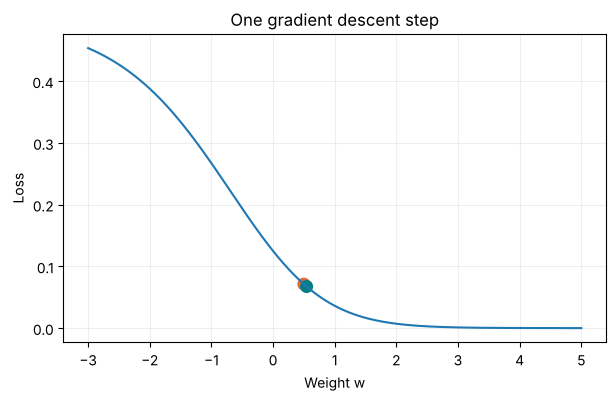

In [4]:
lr = 0.5
w_new = w - lr*grad
print(f"w: {w:.4f} -> {w_new:.4f}")
print(f"loss: {scalar_loss(w):.6f} -> {scalar_loss(w_new):.6f}")
weights = np.linspace(-3, 5, 200)
plt.figure(figsize=(7, 4))
plt.plot(weights, [scalar_loss(t) for t in weights])
plt.scatter([w, w_new], [scalar_loss(w), scalar_loss(w_new)], c=['#de6c38','#007f86'], s=70)
plt.xlabel('Weight w'); plt.ylabel('Loss'); plt.title('One gradient descent step')
plt.grid(alpha=.2); plt.show()

### 질문 1 (셀 4)
**grad가 음수일 때 `w_new = w - lr*grad`에서 w는 어느 쪽으로 움직이나?**

`w_new = w - lr*grad = w + lr*|grad|` 이므로 **w가 증가하는 쪽(오른쪽, +방향)** 으로 움직임. 기울기가 음수라는 것은 w를 키우면 손실이 줄어든다는 뜻이고, 경사하강법은 기울기의 반대 방향으로 가기 때문임.

In [5]:
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
Y = np.array([[0], [1], [1], [0]], dtype=float)
def init_params(seed=7):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(0, 1, (2,4)), 'b1': np.zeros((1,4)),
            'W2': rng.normal(0, 1, (4,1)), 'b2': np.zeros((1,1))}
print(np.column_stack([X,Y]))
print({k: v.shape for k,v in init_params().items()})

[[0. 0. 0.]
 [0. 1. 1.]
 [1. 0. 1.]
 [1. 1. 0.]]
{'W1': (2, 4), 'b1': (1, 4), 'W2': (4, 1), 'b2': (1, 1)}


In [6]:
def forward(X, p):
    H = sigmoid(X @ p['W1'] + p['b1'])
    Z2 = H @ p['W2'] + p['b2']
    P = sigmoid(Z2)
    return H, Z2, P
def bce(Z2, Y):
    return np.mean(np.logaddexp(0, Z2) - Y*Z2)
p0 = init_params()
H, Z2, P = forward(X, p0)
print("initial probabilities:", P.ravel())
print("initial loss:", bce(Z2, Y))

initial probabilities: [0.4668 0.5439 0.4287 0.5097]
initial loss: 0.6993537140706475


In [7]:
def backward(X, Y, H, P, p):
    dZ2 = (P-Y)/len(X)
    dW2 = H.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dH = dZ2 @ p['W2'].T
    dZ1 = dH*H*(1-H)
    return {'W1': X.T @ dZ1, 'b1': dZ1.sum(axis=0, keepdims=True),
            'W2': dW2, 'b2': db2}
def train(lr=1.0, epochs=5000, seed=7):
    p = init_params(seed)
    losses = []
    for epoch in range(epochs):
        H, Z2, P = forward(X, p)
        losses.append(float(bce(Z2, Y)))
        grads = backward(X, Y, H, P, p)
        for name in p:
            p[name] -= lr*grads[name]
    _, Z2, P = forward(X, p)
    losses.append(float(bce(Z2, Y)))
    return p, np.array(losses), P
p, losses, P = train()
print("initial / final loss:", losses[0], losses[-1])
print("x1 x2 / answer / probability / prediction")
print(np.column_stack([X, Y, P, (P>=0.5).astype(int)]))
assert np.all((P>=0.5)==Y)

initial / final loss: 0.6993537140706475 0.0018954622997410984
x1 x2 / answer / probability / prediction
[[0.     0.     0.     0.0012 0.    ]
 [0.     1.     1.     0.9981 1.    ]
 [1.     0.     1.     0.9978 1.    ]
 [1.     1.     0.     0.0024 0.    ]]


### 질문 2 (셀 7)
**backward()의 어느 줄이 셀 3의 `dh_dz = h*(1-h)`에 해당하나?**

`dZ1 = dH*H*(1-H)` 줄의 `H*(1-H)` 부분임. 시그모이드 미분 h(1-h)에 해당하고, 앞의 `dH`는 위에서 내려온 기울기임.

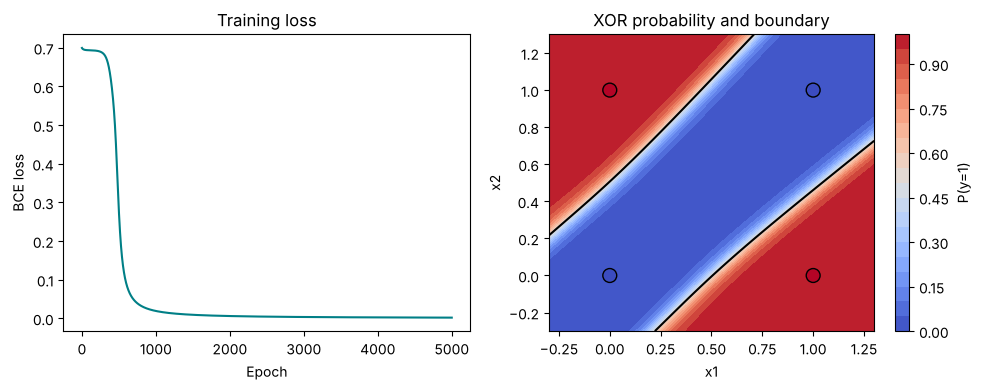

In [8]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(losses, color='#007f86')
axes[0].set(xlabel='Epoch', ylabel='BCE loss', title='Training loss')
grid = np.linspace(-.3,1.3,180)
xx, yy = np.meshgrid(grid,grid)
_, _, pp = forward(np.column_stack([xx.ravel(), yy.ravel()]), p)
zz = pp.reshape(xx.shape)
im = axes[1].contourf(xx, yy, zz, levels=np.linspace(0,1,21), cmap='coolwarm',vmin=0,vmax=1)
axes[1].contour(xx, yy, zz, levels=[.5], colors='black')
axes[1].scatter(X[:,0],X[:,1], c=Y.ravel(),cmap='coolwarm',vmin=0,vmax=1,edgecolors='black',s=100)
axes[1].set(xlabel='x1',ylabel='x2',title='XOR probability and boundary')
fig.colorbar(im, ax=axes[1],label='P(y=1)'); plt.tight_layout(); plt.show()

lr= 0.10, final loss=0.265324, training accuracy=100%


lr= 0.50, final loss=0.004430, training accuracy=100%


lr= 2.00, final loss=0.000870, training accuracy=100%


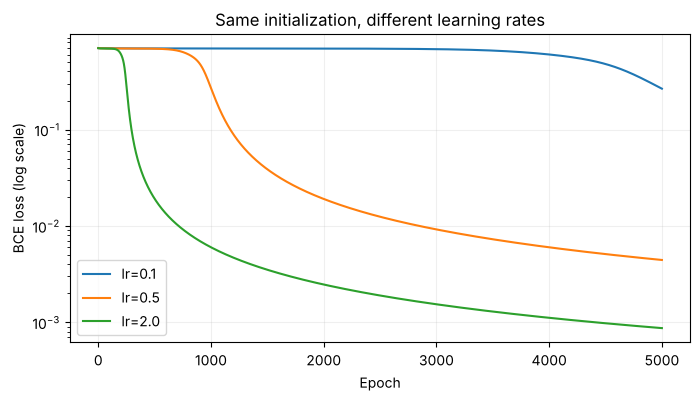

In [9]:
rates = [0.1, 0.5, 2.0]
plt.figure(figsize=(8,4))
for rate in rates:
    _, history, prob = train(lr=rate)
    accuracy = np.mean((prob>=.5)==Y)
    print(f"lr={rate:5.2f}, final loss={history[-1]:.6f}, training accuracy={accuracy:.0%}")
    plt.plot(history, label=f'lr={rate}')
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('BCE loss (log scale)')
plt.title('Same initialization, different learning rates'); plt.legend(); plt.grid(alpha=.2); plt.show()

### 질문 3 (셀 9)
**lr=0.01의 최종 손실이 ln2(≈0.6931) 근처에 머문 이유는?**

- 초기 가중치에서는 네트워크 출력이 모두 0.5 근처라서 BCE 손실이 이미 ln2 ≈ 0.693임. XOR 학습은 이 출력 ≈ 0.5 구간에서 기울기가 매우 작은 평평한 구간(plateau)을 지나야 손실이 떨어짐.
- lr=0.01은 한 번에 움직이는 거리가 너무 작음. 5000 epoch × 0.01 = 누적 학습량 50으로, lr=1.0에서 약 50 epoch 걸리는 양임. lr=1.0도 100 epoch 시점 손실이 0.6934로 아직 평평한 구간이므로, lr=0.01은 이 구간을 벗어나지 못한 채 끝남.
- 즉 모델 용량이 부족해서가 아니라 학습률이 작아 plateau를 못 벗어난 것이며, epoch을 훨씬 늘리면 결국 내려감.

### 과제

| 학습률 | 최종 손실 | 훈련 정확도 | 손실 < 0.5 도달 epoch |
|---|---|---|---|
| 0.1 | 0.2653 | 100% | 4437 |
| 0.5 | 0.004430 | 100% | 890 |
| 2.0 | 0.000870 | 100% | 225 |

세 설정 모두 `seed=7`로 같은 초기 가중치에서 시작하므로, 결과 차이가 초기값이 아니라 학습률 하나 때문이라고 말할 수 있음. 가장 빨리 손실이 줄어든 설정은 lr=2.0으로, 225 epoch에 손실이 0.5 아래로 내려갔고 최종 손실도 가장 낮았음. lr=200처럼 지나치게 크면 발산·진동하므로, 이 문제에서는 2.0 정도까지가 안정적으로 빠른 범위였음.